# MLP on MNIST: training a dense network with backpropagation
784 → 256 → 128 → 10, ReLU, dropout 0.45, Adam, 20 epochs. **Test accuracy 98.1%**. Every line is commented to explain what it does.

In [30]:
import numpy as np # Import the NumPy library for numerical operations, commonly used for array manipulation.
import tensorflow as tf # Import the TensorFlow library, a popular open-source machine learning platform.
import keras # Import the Keras API, a high-level API for building and training deep learning models, now integrated into TensorFlow.
from tensorflow.keras.models import Sequential # Import the Sequential model class from Keras, used to build neural network models layer-by-layer.
from tensorflow.keras.layers import Dense, Dropout, Activation # Import Dense (fully connected layer), Dropout (regularization technique), and Activation (activation function) layers from Keras for building the model.
from tensorflow.keras.utils import to_categorical, plot_model # Import `to_categorical` for one-hot encoding labels and `plot_model` for visualizing model architecture.
from tensorflow.keras.datasets import mnist # Import the MNIST dataset directly from Keras, which contains handwritten digits.
from matplotlib import pyplot as plt # Import Matplotlib's pyplot module for creating plots and visualizations.
import cv2 as cv2 # Import OpenCV (cv2) for computer vision tasks, though not directly used in the current notebook setup.

In [31]:
np.random.seed(1000) # Set the seed for NumPy's random number generator to ensure that results involving random operations are reproducible.

In [32]:
(x_train, y_train),(x_test, y_test) = mnist.load_data() # Load the MNIST dataset, splitting it into training (x_train: images, y_train: labels) and testing (x_test: images, y_test: labels) sets.

unique, counts = np.unique(y_train, return_counts=True) # Count unique values (digits 0-9) and their occurrences in the training labels (y_train).
print(dict(zip(unique, counts))) # Print the distribution of digits in the training set as a dictionary for inspection.

unique, counts = np.unique(y_test, return_counts=True) # Count unique values (digits 0-9) and their occurrences in the testing labels (y_test).
print(dict(zip(unique, counts))) # Print the distribution of digits in the test set as a dictionary.

print(f"\nShape of x_train: {x_train.shape}") # Print the shape (dimensions) of the x_train array (number of samples, height, width).
print(f"First element of y_train: {y_train[0]}") # Print the label of the first training image.
print(f"First image in x_train (first 5x5 pixels):\n{x_train[0,:5,:5]}") # Print the pixel values of the top-left 5x5 region of the first training image.

print(f"\nShape of x_test: {x_test.shape}") # Print the shape (dimensions) of the x_test array.
print(f"First element of y_test: {y_test[0]}") # Print the label of the first testing image.
print(f"First image in x_test (first 5x5 pixels):\n{x_test[0,:5,:5]}") # Print the pixel values of the top-left 5x5 region of the first testing image.

{np.uint8(0): np.int64(5923), np.uint8(1): np.int64(6742), np.uint8(2): np.int64(5958), np.uint8(3): np.int64(6131), np.uint8(4): np.int64(5842), np.uint8(5): np.int64(5421), np.uint8(6): np.int64(5918), np.uint8(7): np.int64(6265), np.uint8(8): np.int64(5851), np.uint8(9): np.int64(5949)}
{np.uint8(0): np.int64(980), np.uint8(1): np.int64(1135), np.uint8(2): np.int64(1032), np.uint8(3): np.int64(1010), np.uint8(4): np.int64(982), np.uint8(5): np.int64(892), np.uint8(6): np.int64(958), np.uint8(7): np.int64(1028), np.uint8(8): np.int64(974), np.uint8(9): np.int64(1009)}

Shape of x_train: (60000, 28, 28)
First element of y_train: 5
First image in x_train (first 5x5 pixels):
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]

Shape of x_test: (10000, 28, 28)
First element of y_test: 7
First image in x_test (first 5x5 pixels):
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]


In [33]:
num_labels = len(np.unique(y_train)) # Calculate the number of unique classes (digits) present in the training labels.
print(num_labels) # Print the calculated number of unique labels to confirm it's 10 for MNIST.

10


In [34]:
y_train = to_categorical(y_train) # Convert integer labels of the training set into one-hot encoded vectors (e.g., digit '5' becomes [0,0,0,0,0,1,0,0,0,0]). This is required for 'categorical_crossentropy' loss.
y_test = to_categorical(y_test) # Convert integer labels of the test set into one-hot encoded vectors.
print(y_train[0]) # Print the one-hot encoded label of the first training image to verify the transformation.
print(y_train[45]) # Print another one-hot encoded label for further verification.

[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


In [35]:
image_size = x_train.shape[1] # Extract the height (or width, since images are square) of the images from the x_train shape.
print(x_train.shape) # Print the current shape of the x_train dataset (e.g., (60000, 28, 28)).
print(image_size) # Print the determined image size (e.g., 28).
input_size = image_size * image_size # Calculate the total number of pixels in a flattened image (e.g., 28 * 28 = 784), which will be the input dimension for the first dense layer.
print(input_size) # Print the calculated input size.

(60000, 28, 28)
28
784


In [36]:
x_train = np.reshape(x_train, [-1, input_size]) # Reshape training images from their original 2D format (28x28) to a 1D vector (784 pixels). The '-1' automatically infers the number of samples (60000).
print(f"Shape of x_train after reshape: {x_train.shape}") # Print the shape of x_train after reshaping.
print(f"Dtype of x_train before normalization: {x_train.dtype}") # Print the data type of x_train before the normalization step.
print(f"First 5 pixels of x_train before normalization (first image): {x_train[0,:5]}") # Print the first 5 pixel values of the first training image before normalization.

x_train = x_train.astype('float32') / 255 # Convert x_train data type to float32 and normalize pixel values from the original [0, 255] range to [0.0, 1.0]. This aids in model training stability and performance.
print(f"Shape of x_train after normalization: {x_train.shape}") # Print the shape of x_train after normalization (it should be the same as after reshape).
print(f"Dtype of x_train after normalization: {x_train.dtype}") # Print the data type of x_train after normalization.
print(f"First 5 pixels of x_train after normalization (first image): {x_train[0,:5]}") # Print the first 5 pixel values of the first training image after normalization.

x_test = np.reshape(x_test, [-1, input_size]) # Reshape test images from 2D (28x28) to 1D (784 pixels).
x_test = x_test.astype('float32') / 255 # Convert x_test data type to float32 and normalize pixel values from [0, 255] to [0.0, 1.0].
print(f"Shape of x_test after normalization: {x_test.shape}") # Print the shape of x_test after normalization.
print(f"Dtype of x_test after normalization: {x_test.dtype}") # Print the data type of x_test after normalization.

Shape of x_train after reshape: (60000, 784)
Dtype of x_train before normalization: uint8
First 5 pixels of x_train before normalization (first image): [0 0 0 0 0]
Shape of x_train after normalization: (60000, 784)
Dtype of x_train after normalization: float32
First 5 pixels of x_train after normalization (first image): [0. 0. 0. 0. 0.]
Shape of x_test after normalization: (10000, 784)
Dtype of x_test after normalization: float32


In [37]:
input_shape = (image_size, image_size, 1) # Define the input shape for models that might expect 2D image input (height, width, channels), e.g., for CNNs.
batch_size =128 # Set the batch size, which is the number of samples processed before the model's weights are updated during training.
dropout = 0.45 # Set the dropout rate, a regularization technique where 45% of neurons are randomly ignored during training to prevent overfitting.
num_labels = 10 # Correcting num_labels to 10 for MNIST dataset # Explicitly set the number of output classes to 10, as MNIST contains digits from 0 to 9.

In [38]:
model = Sequential() # Initialize a Sequential Keras model, allowing layers to be added one after another linearly.
model.add(Dense(256,input_dim=input_size, activation='relu')) # Add the first fully connected (Dense) layer with 256 neurons. 'input_dim' specifies the number of input features (784 pixels from the flattened images). 'relu' (Rectified Linear Unit) is used as the activation function.
model.add(Dropout(dropout)) # Add a Dropout layer with the specified 'dropout' rate (0.45). This layer randomly sets a fraction of input units to 0 at each update during training, which helps prevent overfitting.

model.add(Dense(128, activation='relu')) # Add a second fully connected (Dense) hidden layer with 128 neurons and a 'relu' activation function.
model.add(Dropout(dropout)) # Add another Dropout layer to further prevent overfitting by randomly dropping out 45% of neurons in this layer.

model.add(Dense(num_labels, activation='softmax')) # Add the output layer with 'num_labels' (10) neurons, corresponding to the 10 digit classes. 'softmax' activation ensures the output is a probability distribution over the classes, summing to 1.

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [39]:
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [40]:
history = model.fit(x_train, y_train, epochs=20,batch_size= batch_size,validation_split=0.2) # Train the model using the training data. 'epochs' is the number of times the model will see the entire dataset, 'batch_size' determines how many samples are processed before updating model weights, and 'validation_split' sets aside 20% of the training data for validation during training.
_, acc = model.evaluate(x_test, y_test, batch_size=batch_size, verbose=0) # Evaluate the trained model's performance on the unseen test dataset. 'evaluate' returns the loss and metrics; we're interested in the accuracy ('acc'). 'batch_size' is used for evaluation efficiency, and 'verbose=0' suppresses output during evaluation.
print("\nTest accuracy: %.1f%%" % (100.0 * acc)) # Print the final test accuracy as a percentage. This gives a measure of how well the model generalizes to new, unseen data.

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.8365 - loss: 0.5314 - val_accuracy: 0.9455 - val_loss: 0.1790
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9292 - loss: 0.2381 - val_accuracy: 0.9605 - val_loss: 0.1296
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9456 - loss: 0.1857 - val_accuracy: 0.9670 - val_loss: 0.1103
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9549 - loss: 0.1538 - val_accuracy: 0.9680 - val_loss: 0.1021
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9596 - loss: 0.1379 - val_accuracy: 0.9691 - val_loss: 0.0988
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9636 - loss: 0.1207 - val_accuracy: 0.9721 - val_loss: 0.0929
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9661 - loss: 0.1143 - val_accuracy: 0.9730 - val_loss: 0.0902
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9695 - loss: 0.1031 - val_accurac

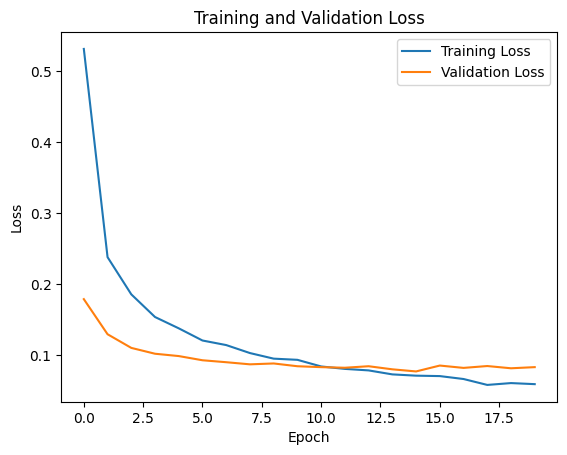

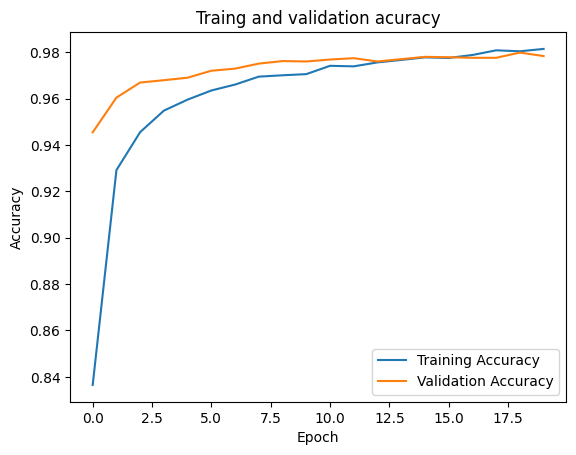

In [41]:
plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label= 'Validation Accuracy')
plt.title('Traing and validation acuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


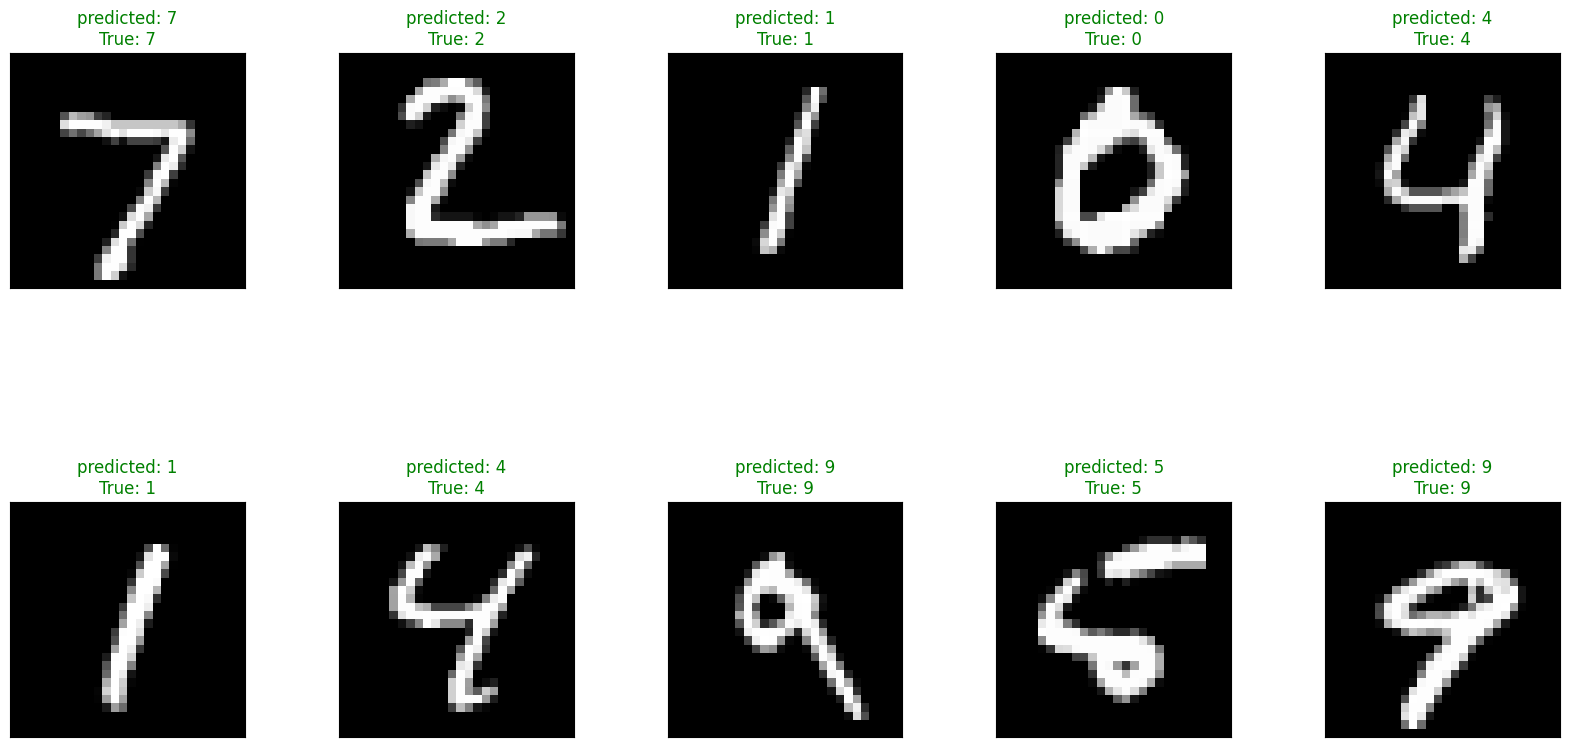

In [46]:
# Ensure x_test is in flattened format for model prediction
# This is necessary because x_test might have been reshaped for plotting in a previous run
x_test_flattened = x_test.reshape(-1, input_size)

predictions = model.predict(x_test_flattened[:10]) # Predict on the first 10 flattened test images
predicted_labels = tf.argmax(predictions, axis=1)
true_labels = tf.argmax(y_test[:10], axis=1)

fig, axs = plt.subplots(2, 5, figsize=(20, 10))
fig.subplots_adjust(hspace=0.4, wspace=0.4)

# Create a separate variable for the 2D image format needed for plotting
x_test_images = x_test_flattened.reshape(-1, 28, 28)

for i, ax in enumerate(axs.flat):

  ax.imshow(x_test_images[i], cmap='gray') # Use cmap for grayscale, not camp
  ax.set_xticks([])
  ax.set_yticks([])

  pred_label = predicted_labels[i].numpy()
  true_label = true_labels[i].numpy()

  if pred_label == true_label:
    ax.set_title("predicted: {}\nTrue: {}".format(pred_label, true_label),color='green')

  else:
    ax.set_title("Predicted: {}\nTrue: {}".format(pred_label, true_label),color='red')

plt.show()